# Snack-Klassifikation

In [ ]:
from datetime import datetime
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.datasets import ImageFolder

ROOT = Path.cwd()
DATA = ROOT / "data/snack_classification"
DATASET = DATA / "dataset"
WEIGHTS = ROOT / "models/snack_classification_mobilenet_v3_small.pt"
SPLITS = ("train", "val", "test")
CLASSES = ["Bounty", "Snickers"]
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

if not DATASET.is_dir() or not WEIGHTS.is_file():
    raise FileNotFoundError(f"Projektordner öffnen. Erwartet: {DATASET} und {WEIGHTS}")
if DEVICE == "cpu":
    torch.set_num_threads(4)

print(f"Gerät: {DEVICE}")
print(f"Modell: {WEIGHTS.name}")

# Fotos beschriften und Datensatz vorbereiten

train: 15 Bilder
val: 5 Bilder
test: 5 Bilder


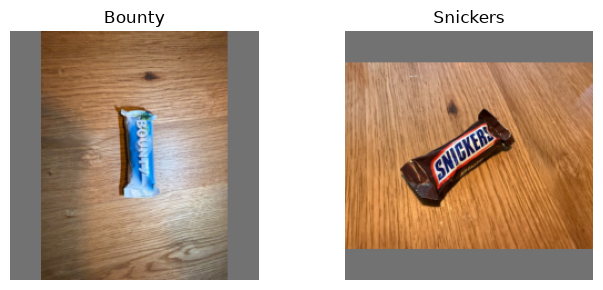

In [2]:
def resize_image(image):
    image = ImageOps.exif_transpose(image).convert("RGB")
    return ImageOps.pad(image, (224, 224), method=Image.Resampling.BILINEAR,
                        color=(114, 114, 114))


preprocess = transforms.Compose([
    transforms.Lambda(resize_image),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
datasets = {split: ImageFolder(DATASET / split, transform=preprocess) for split in SPLITS}

for split, dataset in datasets.items():
    print(f"{split}: {len(dataset)} Bilder")

fig, axes = plt.subplots(1, len(CLASSES), figsize=(7, 3))
for ax, label in zip(axes, CLASSES):
    photo = next((DATASET / "train" / label).glob("*.jpg"))
    ax.imshow(resize_image(Image.open(photo)))
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

# MobileNetV3 laden und optional weitertrainieren

In [ ]:
TRAIN = False
EPOCHS = 3


def load_classifier(weights):
    checkpoint = torch.load(weights, map_location="cpu", weights_only=True)
    model = models.mobilenet_v3_small(weights=None)
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASSES))
    model.load_state_dict(checkpoint["state_dict"])
    return model.to(DEVICE).eval(), checkpoint


model, checkpoint = load_classifier(WEIGHTS)

if TRAIN:
    run = ROOT / "runs/snack_classification" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    run.mkdir(parents=True)
    trained_weights = run / WEIGHTS.name
    train_loader = DataLoader(datasets["train"], batch_size=4, shuffle=True)
    val_loader = DataLoader(datasets["val"], batch_size=4)
    model.features.requires_grad_(False)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=0.0001)
    best_loss = float("inf")

    for epoch in range(1, EPOCHS + 1):
        model.classifier.train()
        for images, labels in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(images.to(DEVICE)), labels.to(DEVICE))
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss = 0.0
        with torch.inference_mode():
            for images, labels in val_loader:
                loss = loss_fn(model(images.to(DEVICE)), labels.to(DEVICE))
                val_loss += loss.item() * len(labels)
        val_loss /= len(datasets["val"])
        print(f"Epoche {epoch}: Validierungsverlust {val_loss:.4f}")

        if val_loss < best_loss:
            best_loss = val_loss
            torch.save({
                "architecture": checkpoint["architecture"],
                "classes": checkpoint["classes"],
                "state_dict": model.state_dict(),
                "epoch": epoch,
                "image_size": checkpoint["image_size"],
            }, trained_weights)

    model, checkpoint = load_classifier(trained_weights)
    print(f"Gespeichert: {trained_weights.relative_to(ROOT)}")

# Ergebnisse des mitgelieferten Modells

Testgenauigkeit: 100% (5/5)


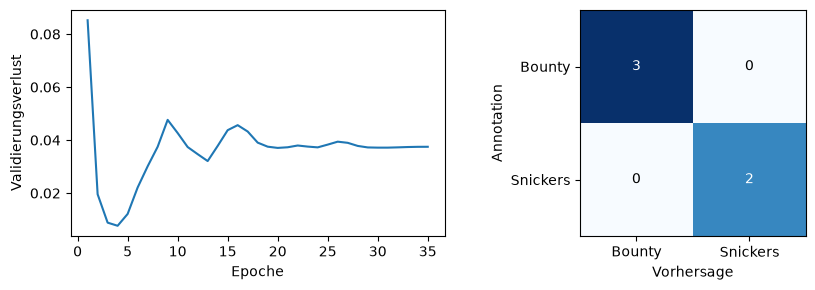

In [4]:
results = DATA / "results"
history = json.loads((results / "history.json").read_text())
metrics = json.loads((results / "metrics.json").read_text())
test = metrics["test"]
print(f"Testgenauigkeit: {test['accuracy']:.0%} ({test['correct']}/{test['total']})")

fig, (curve, matrix) = plt.subplots(1, 2, figsize=(9, 3))
curve.plot([row["epoch"] for row in history], [row["loss"] for row in history])
curve.set(xlabel="Epoche", ylabel="Validierungsverlust")
matrix.matshow(test["confusion_matrix"], cmap="Blues")
matrix.set(xticks=range(len(CLASSES)), xticklabels=CLASSES,
           yticks=range(len(CLASSES)), yticklabels=CLASSES,
           xlabel="Vorhersage", ylabel="Annotation")
matrix.xaxis.set_ticks_position("bottom")
for row, values in enumerate(test["confusion_matrix"]):
    for column, count in enumerate(values):
        matrix.text(column, row, count, ha="center", va="center",
                    color="white" if count > 1 else "black")
plt.tight_layout()
plt.show()

# Testbilder klassifizieren

Die Vorhersage zeigt die Klasse mit dem höchsten Modellwert. Unter 75 % zeigt
die Demo „Unsicher“. Das Modell kennt die beiden trainierten Klassen.

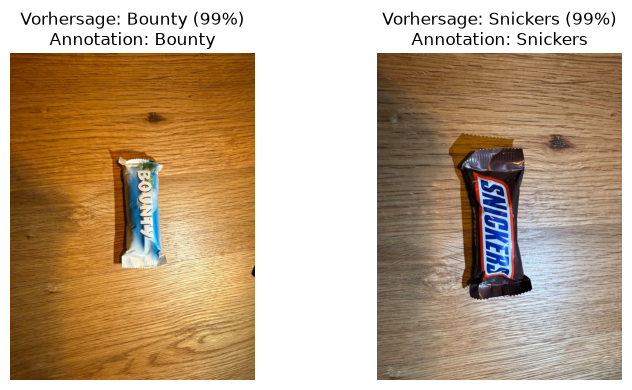

In [5]:
THRESHOLD = 0.75


@torch.inference_mode()
def classify(image):
    tensor = preprocess(image).unsqueeze(0).to(DEVICE)
    probabilities = model(tensor).softmax(dim=1)[0].cpu()
    index = int(probabilities.argmax())
    confidence = float(probabilities[index])
    label = checkpoint["classes"][index] if confidence >= THRESHOLD else "Unsicher"
    return label, confidence


fig, axes = plt.subplots(1, len(CLASSES), figsize=(8, 4))
for ax, expected in zip(axes, CLASSES):
    photo = sorted((DATASET / "test" / expected).glob("*.jpg"))[0]
    with Image.open(photo) as image:
        label, confidence = classify(image)
        ax.imshow(ImageOps.exif_transpose(image))
    ax.set_title(f"Vorhersage: {label} ({confidence:.0%})\nAnnotation: {expected}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Live-Klassifikation

In [ ]:
USE_CAMERA = True
CAMERA = 0

if USE_CAMERA:
    camera = cv2.VideoCapture(CAMERA)
    window = "Snack-Klassifikation | Q / Esc"
    try:
        if not camera.isOpened():
            raise RuntimeError(f"Kamera {CAMERA} lässt sich nicht öffnen.")

        while True:
            ok, frame = camera.read()
            if not ok:
                raise RuntimeError("Die Kamera liefert kein Bild.")

            height, width = frame.shape[:2]
            side = int(0.8 * min(height, width))
            x, y = (width - side) // 2, (height - side) // 2
            crop = frame[y:y + side, x:x + side]
            image = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
            label, confidence = classify(image)
            cv2.rectangle(frame, (x, y), (x + side, y + side), (0, 220, 0), 2)
            cv2.putText(frame, f"{label}: {confidence:.0%}", (15, 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 220, 0), 2)

            cv2.imshow(window, frame)
            if cv2.waitKey(1) & 0xFF in (ord("q"), 27):
                break
            if cv2.getWindowProperty(window, cv2.WND_PROP_VISIBLE) < 1:
                break
    finally:
        camera.release()
        cv2.destroyAllWindows()